# 06 - Évaluation du Modèle Final (model_07199.pt)

Ce notebook charge spécifiquement le modèle `.pt` choisi, applique l'inférence sur le jeu de validation, compare avec la vérité terrain (Ground Truth) et calcule les performances (Précision, Rappel, Objets détectés vs réels).

In [ ]:
import os, cv2
import re
import sys
import json
from pathlib import Path
import torch
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# Detect environment
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT_DIR = Path('/content/drive/MyDrive/INSEG_PRO')
    if not PROJECT_DIR.exists():
        raise FileNotFoundError(
            f'Google Drive project folder not found: {PROJECT_DIR}. '
            'Update PROJECT_DIR in this cell to your actual path.'
        )
else:
    PROJECT_DIR = Path('/home/rachidjunior/VS_Code/INSEG_PRO')

DATA_DIR = PROJECT_DIR / 'data' / 'raw'
OUTPUTS_ROOT = PROJECT_DIR / 'outputs'

BEST_MODEL_PATH = OUTPUTS_ROOT / 'mask_rcnn_cityscapes_colab' / 'model_0007199.pth'

sys.path.insert(0, str(PROJECT_DIR / 'data'))
print(f"Project Dir: {PROJECT_DIR}")
print(f"Model Path: {BEST_MODEL_PATH}")
print(f"Model Exists: {BEST_MODEL_PATH.exists()}")

# Add project modules to path
sys.path.insert(0, str(PROJECT_DIR / 'data'))
sys.path.insert(0, str(PROJECT_DIR))

print('=' * 70)
print('SETUP - EVALUATION (LOCAL/COLAB)')
print('=' * 70)
print(f'Running on Colab: {IN_COLAB}')
print(f'Project: {PROJECT_DIR}')
print(f'Data: {DATA_DIR}')
print(f'Outputs root: {OUTPUTS_ROOT}')
print(f'GPU available: {torch.cuda.is_available()}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project Dir: /content/drive/MyDrive/INSEG_PRO
Model Path: /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0007199.pth
Model Exists: True
SETUP - EVALUATION (LOCAL/COLAB)
Running on Colab: True
Project: /content/drive/MyDrive/INSEG_PRO
Data: /content/drive/MyDrive/INSEG_PRO/data/raw
Outputs root: /content/drive/MyDrive/INSEG_PRO/outputs
GPU available: False


In [ ]:
print('=' * 70)
print('STEP 2 - INSTALL DEPENDENCIES')
print('=' * 70)

import sys
import site
import pkgutil
import subprocess
import importlib.machinery
from pathlib import Path

CODE_DIR = PROJECT_DIR / 'code'

# Compatibility shims for old pkg_resources implementations on newer Python.
if not hasattr(pkgutil, 'ImpImporter'):
    pkgutil.ImpImporter = pkgutil.zipimporter
if not hasattr(importlib.machinery.FileFinder, 'find_module'):
    def _ff_find_module(self, fullname):
        spec = self.find_spec(fullname)
        return spec.loader if spec else None
    importlib.machinery.FileFinder.find_module = _ff_find_module

# Prefer /usr/local site-packages over distro packages.
for p in reversed([x for x in site.getsitepackages() if x.startswith('/usr/local')]):
    if p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)

REQ_FILE_CODE = CODE_DIR / 'requirements.txt'
REQ_FILE_PROJECT = PROJECT_DIR / 'requirements.txt'
REQ_FILE = REQ_FILE_CODE if REQ_FILE_CODE.exists() else REQ_FILE_PROJECT

def run_pip(args):
    cmd = [sys.executable, '-m', 'pip'] + args
    print('Running:', ' '.join(cmd))
    subprocess.check_call(cmd)

# Bootstrap packaging tools.
run_pip(['install', '-q', '--upgrade', 'pip', 'wheel', 'setuptools>=75.0.0', 'packaging', 'jedi'])

installed_from_requirements = False
if REQ_FILE.exists():
    print(f'Using requirements file: {REQ_FILE}')
    try:
        run_pip(['install', '-q', '-r', str(REQ_FILE)])
        installed_from_requirements = True
    except subprocess.CalledProcessError:
        print('requirements.txt install failed, switching to fallback dependency set...')
else:
    print('No requirements.txt found in code/ or project root.')

if not installed_from_requirements:
    fallback_packages = [
        'torch>=2.0.0',
        'torchvision>=0.15.0',
        'torchaudio>=2.0.0',
        'opencv-python>=4.8.0',
        'Pillow>=10.0.0',
        'albumentations>=1.3.0',
        'numpy>=1.24.0',
        'pandas>=2.0.0',
        'matplotlib>=3.7.0',
        'seaborn>=0.12.0',
        'tqdm>=4.65.0',
        'pyyaml>=6.0',
        'pycocotools>=2.0.0',
        'ipywidgets>=8.0.0'
    ]
    run_pip(['install', '-q', *fallback_packages])

# Install Detectron2.
run_pip(['install', '-q', '--no-build-isolation', 'git+https://github.com/facebookresearch/detectron2.git'])

# Re-apply shims before import checks.
if not hasattr(pkgutil, 'ImpImporter'):
    pkgutil.ImpImporter = pkgutil.zipimporter
if not hasattr(importlib.machinery.FileFinder, 'find_module'):
    def _ff_find_module(self, fullname):
        spec = self.find_spec(fullname)
        return spec.loader if spec else None
    importlib.machinery.FileFinder.find_module = _ff_find_module

import detectron2
from detectron2 import model_zoo
print('Detectron2 installed:', detectron2.__version__)
print('Detectron2 import test: OK')

STEP 2 - INSTALL DEPENDENCIES
Running: /usr/bin/python3 -m pip install -q --upgrade pip wheel setuptools>=75.0.0 packaging jedi
Using requirements file: /content/drive/MyDrive/INSEG_PRO/requirements.txt
Running: /usr/bin/python3 -m pip install -q -r /content/drive/MyDrive/INSEG_PRO/requirements.txt
Running: /usr/bin/python3 -m pip install -q --no-build-isolation git+https://github.com/facebookresearch/detectron2.git
Detectron2 installed: 0.6
Detectron2 import test: OK


In [ ]:
# Fixed path layout for your Drive structure.

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f'Project folder not found at: {PROJECT_DIR}. '
        'Upload/copy INSEG_PRO to Drive and update PROJECT_DIR.'
    )

if not CODE_DIR.exists():
    raise FileNotFoundError(
        f'Code folder not found at: {CODE_DIR}. '
        'Expected INSEG_PRO/code in Google Drive.'
    )

# Your dataset loader is at INSEG_PRO/code/dataset_loader.py.
DATASET_LOADER_PATH = CODE_DIR / 'dataset_loader.py'
if not DATASET_LOADER_PATH.exists():
    raise FileNotFoundError(
        f'dataset_loader.py not found at: {DATASET_LOADER_PATH}'
    )

%cd {CODE_DIR}
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

print('Project directory:', PROJECT_DIR)
print('Code directory   :', CODE_DIR)
print('dataset_loader   :', DATASET_LOADER_PATH)
print('requirements in code dir   :', (CODE_DIR / 'requirements.txt').exists())
print('requirements in project dir:', (PROJECT_DIR / 'requirements.txt').exists())

/content/drive/MyDrive/INSEG_PRO/code
Project directory: /content/drive/MyDrive/INSEG_PRO
Code directory   : /content/drive/MyDrive/INSEG_PRO/code
dataset_loader   : /content/drive/MyDrive/INSEG_PRO/code/dataset_loader.py
requirements in code dir   : False
requirements in project dir: True


In [ ]:
# Import and load datasets
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

import dataset_loader
try:
    val_dataset_name, val_dicts, val_metadata = dataset_loader.register_cityscapes_dataset(DATA_DIR, split='val')
    print(f'\n✅ Dataset validation chargé: {len(val_dicts)} images trouvées.')
except Exception as e:
    print(f'❌ Erreur de chargement: {e}')


✅ Dataset validation chargé: 492 images trouvées.


In [ ]:
# Charger le modèle
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file('COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml'))
cfg.DATASETS.TEST = (val_dataset_name,)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(dataset_loader.CITYSCAPES_THING_CLASSES)
cfg.MODEL.WEIGHTS = str(BEST_MODEL_PATH)
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # Seuil de détection
cfg.MODEL.DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

predictor = DefaultPredictor(cfg)
print(f"\n✅ Modèle chargé en mode inférence sur {cfg.MODEL.DEVICE.upper()}")


✅ Modèle chargé en mode inférence sur CPU


## 1. Visualisation: Prédictions vs Vérité Terrain (Ground Truth)

Analyse détaillée sur un échantillon de 10 images :



/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W0402 22:46:51.084000 15250 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


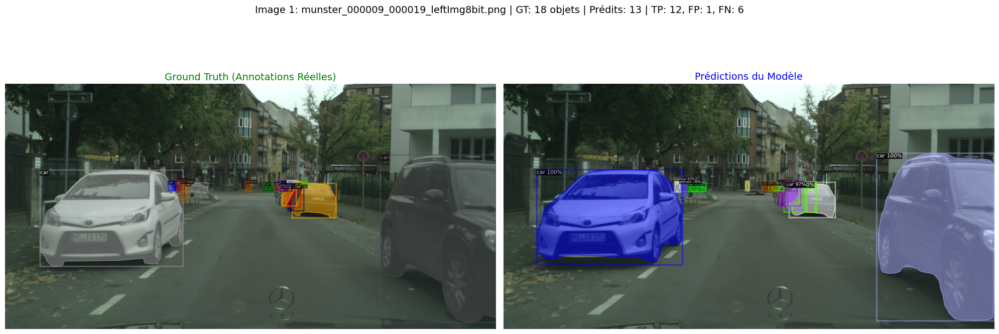

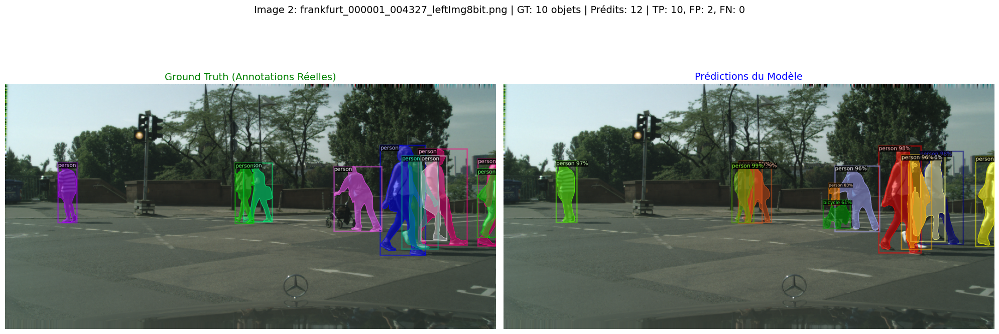

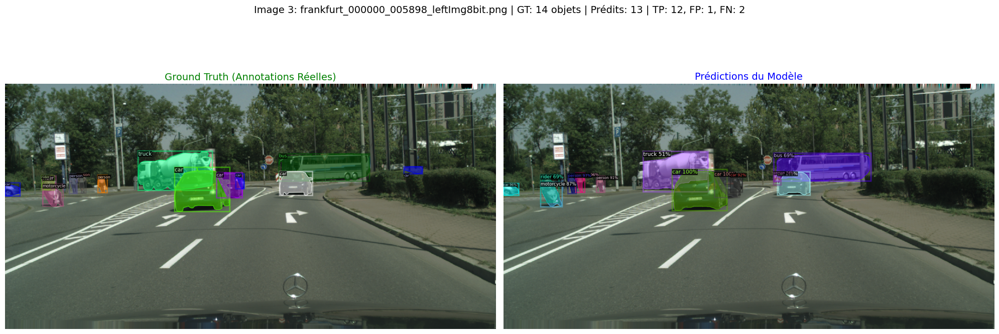

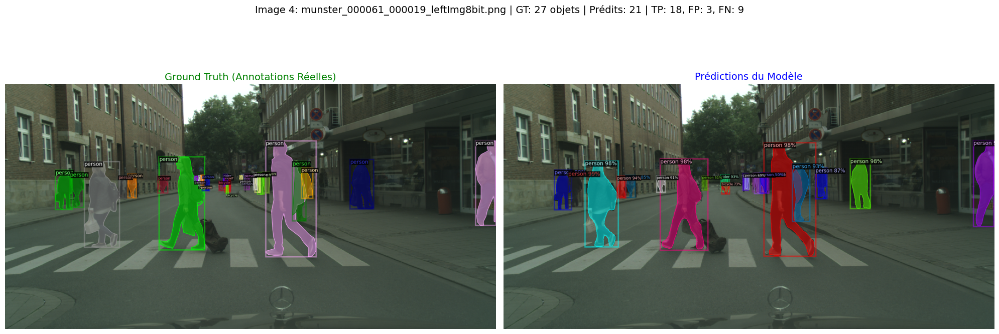

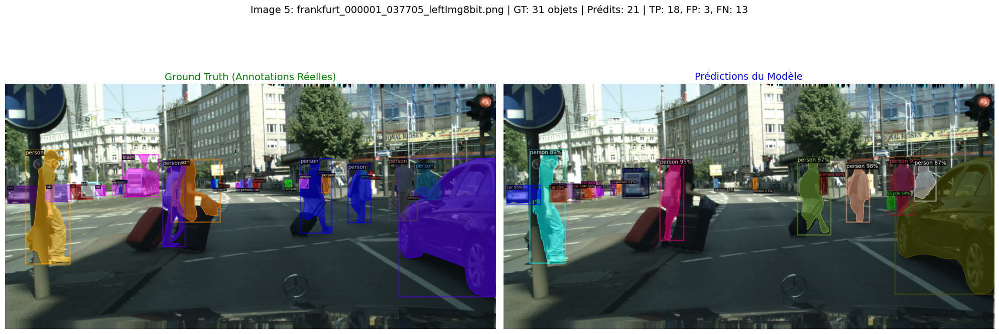

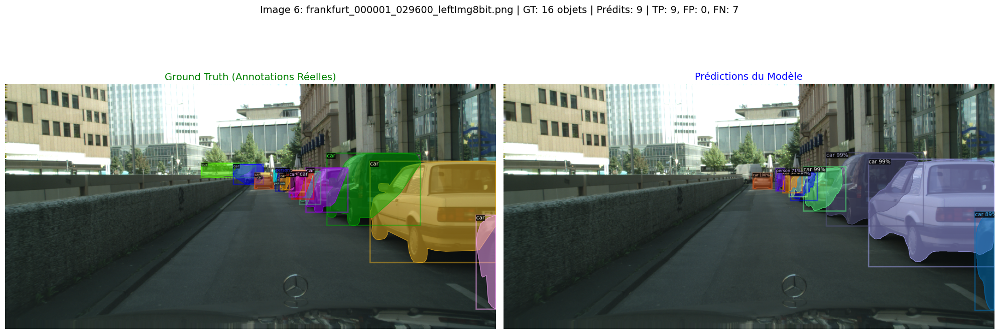

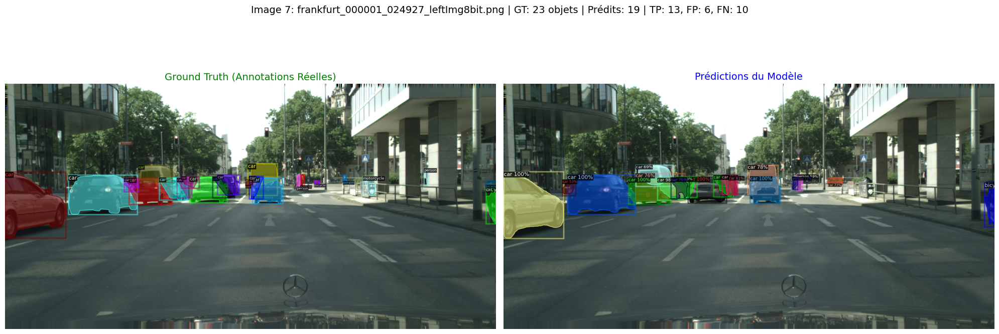

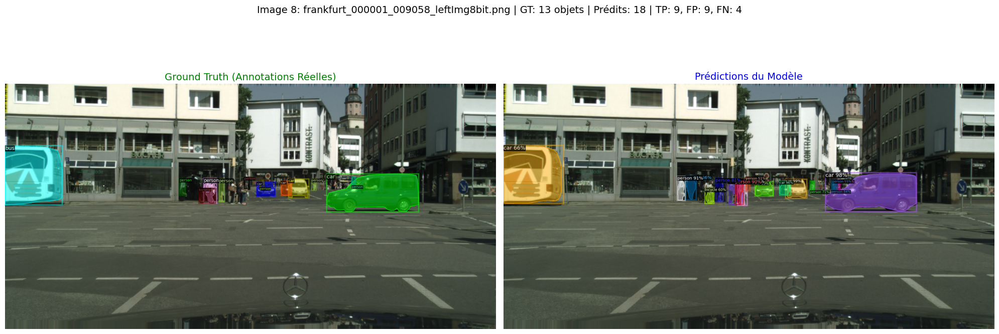

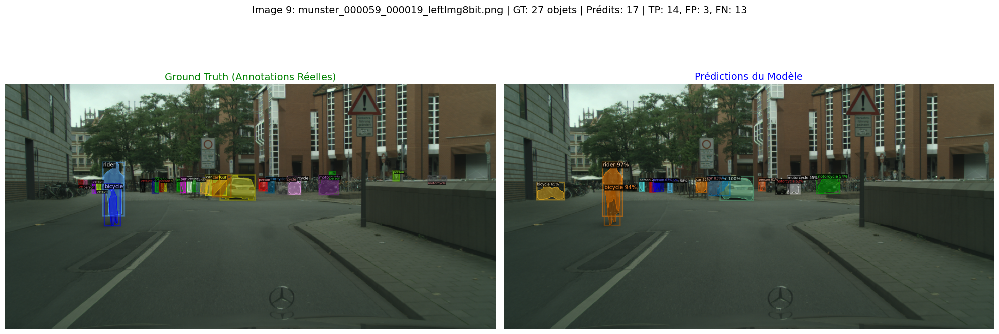

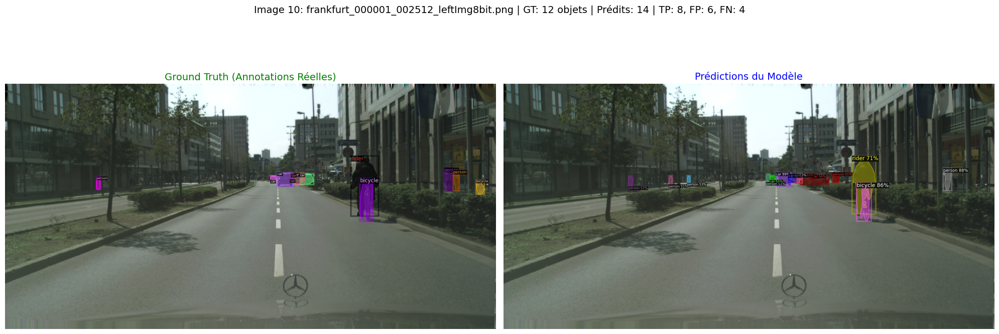

📊 RÉSUMÉ DES STATISTIQUES SUR LES 10 IMAGES
📦 Objets Réels (GT) : 191
🔍 Objets Détectés   : 157
--------------------------------------------------
✅ Vrais Positifs (TP) : 123
❌ Faux Positifs (FP)  : 34
👻 Faux Négatifs (FN)  : 68
--------------------------------------------------
📈 Précision : 78.34%
📉 Rappel    : 64.40%


In [ ]:
from detectron2.utils.visualizer import Visualizer
from torchvision.ops import box_iou

NUM_IMAGES = 10
IOU_THRESHOLD = 0.5

# Fixer la seed pour avoir un échantillon reproductible et varié
random.seed(42)
sample_dicts = random.sample(val_dicts, min(NUM_IMAGES, len(val_dicts))) if len(val_dicts)>0 else []

total_gt = 0
total_pred = 0
total_tp = 0
total_fp = 0

print(f"Analyse détaillée sur un échantillon de {len(sample_dicts)} images :\n")

for i, d in enumerate(sample_dicts):
    img = cv2.imread(d['file_name'])
    if img is None: continue

    # --- Inférence ---
    with torch.no_grad():
        outputs = predictor(img)

    pred_instances = outputs["instances"].to("cpu")
    pred_boxes = pred_instances.pred_boxes.tensor
    num_pred = len(pred_boxes)

    # --- Ground Truth ---
    gt_boxes = [ann['bbox'] for ann in d.get('annotations', [])]
    gt_boxes = torch.tensor(gt_boxes, dtype=torch.float32)
    num_gt = len(gt_boxes)

    # --- Stats pour cette image ---
    tp = 0
    if num_pred > 0 and num_gt > 0:
        iou_matrix = box_iou(pred_boxes, gt_boxes)
        max_ious, _ = iou_matrix.max(dim=1)
        tp = (max_ious >= IOU_THRESHOLD).sum().item()

    fp = num_pred - tp
    fn = num_gt - tp

    total_gt += num_gt
    total_pred += num_pred
    total_tp += tp
    total_fp += fp

    # --- Visualisation ---
    v_pred = Visualizer(img[:, :, ::-1], metadata=val_metadata, scale=0.8)
    v_pred = v_pred.draw_instance_predictions(pred_instances)
    img_pred = v_pred.get_image()[:, :, ::-1]

    v_gt = Visualizer(img[:, :, ::-1], metadata=val_metadata, scale=0.8)
    v_gt = v_gt.draw_dataset_dict(d)
    img_gt = v_gt.get_image()[:, :, ::-1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    fig.suptitle(f"Image {i+1}: {Path(d['file_name']).name} | GT: {num_gt} objets | Prédits: {num_pred} | TP: {tp}, FP: {fp}, FN: {fn}", fontsize=14)

    ax1.imshow(cv2.cvtColor(img_gt, cv2.COLOR_BGR2RGB))
    ax1.set_title("Ground Truth (Annotations Réelles)", color='green', fontsize=14)
    ax1.axis('off')

    ax2.imshow(cv2.cvtColor(img_pred, cv2.COLOR_BGR2RGB))
    ax2.set_title("Prédictions du Modèle", color='blue', fontsize=14)
    ax2.axis('off')

    plt.tight_layout()
    plt.show()

# --- Résumé des statistiques sur l'échantillon ---
total_fn = total_gt - total_tp
precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0

print("="*50)
print(f"📊 RÉSUMÉ DES STATISTIQUES SUR LES {len(sample_dicts)} IMAGES")
print("="*50)
print(f"📦 Objets Réels (GT) : {total_gt}")
print(f"🔍 Objets Détectés   : {total_pred}")
print("-" * 50)
print(f"✅ Vrais Positifs (TP) : {total_tp}")
print(f"❌ Faux Positifs (FP)  : {total_fp}")
print(f"👻 Faux Négatifs (FN)  : {total_fn}")
print("-" * 50)
print(f"📈 Précision : {precision*100:.2f}%")
print(f"📉 Rappel    : {recall*100:.2f}%")
print("="*50)